## Project 2: Recommendation and Influence Analysis

**Goal:** Model a user-item interaction network and identify influential users and candidate recommendations.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx

# ═══════════════════════════════════════════════════════════════════════
# PROJECT 2 — Recommendation Network
# Bipartite graph: Users on one side, Products on the other.
# Edge = user purchased/liked that product.
# ═══════════════════════════════════════════════════════════════════════

# Build a bipartite graph
REC = nx.Graph()

users    = ["U1", "U2", "U3", "U4", "U5"]
products = ["P_Laptop", "P_Phone", "P_Tablet", "P_Headphones", "P_Keyboard", "P_Mouse"]

# Add nodes with a 'bipartite' attribute (0=users, 1=products)
REC.add_nodes_from(users,    bipartite=0)
REC.add_nodes_from(products, bipartite=1)

# Purchases: (user, product)
purchases = [
    ("U1", "P_Laptop"), ("U1", "P_Phone"),    ("U1", "P_Headphones"),
    ("U2", "P_Phone"),  ("U2", "P_Tablet"),   ("U2", "P_Headphones"),
    ("U3", "P_Laptop"), ("U3", "P_Keyboard"), ("U3", "P_Mouse"),
    ("U4", "P_Tablet"), ("U4", "P_Keyboard"),
    ("U5", "P_Phone"),  ("U5", "P_Mouse"),
]
REC.add_edges_from(purchases)



## Basic Strcuture

In [2]:
print("=" * 60)
print("PROJECT 2 — RECOMMENDATION NETWORK ANALYSIS")
print("=" * 60)

print(f"\nUsers    : {users}")
print(f"Products : {products}")
print(f"Total edges (purchases): {REC.number_of_edges()}")

# Most popular products (highest degree)
product_degrees = {p: REC.degree(p) for p in products}
print("\nProduct popularity (number of buyers):")
for prod, deg in sorted(product_degrees.items(), key=lambda x: -x[1]):
    buyers = list(REC.neighbors(prod))
    print(f"  {prod:16s}: {deg} buyers → {buyers}")



PROJECT 2 — RECOMMENDATION NETWORK ANALYSIS

Users    : ['U1', 'U2', 'U3', 'U4', 'U5']
Products : ['P_Laptop', 'P_Phone', 'P_Tablet', 'P_Headphones', 'P_Keyboard', 'P_Mouse']
Total edges (purchases): 13

Product popularity (number of buyers):
  P_Phone         : 3 buyers → ['U1', 'U2', 'U5']
  P_Laptop        : 2 buyers → ['U1', 'U3']
  P_Tablet        : 2 buyers → ['U2', 'U4']
  P_Headphones    : 2 buyers → ['U1', 'U2']
  P_Keyboard      : 2 buyers → ['U3', 'U4']
  P_Mouse         : 2 buyers → ['U3', 'U5']


## User2User Similarity

In [3]:
# ── User-User similarity via common purchases ────────────────────────
print("\n── User-User similarity (shared purchases): ──")

USER_SIM = nx.Graph()
USER_SIM.add_nodes_from(users)

for i in range(len(users)):
    for j in range(i+1, len(users)):
        u1, u2 = users[i], users[j]
        items_u1 = set(REC.neighbors(u1))
        items_u2 = set(REC.neighbors(u2))
        shared   = items_u1 & items_u2  # intersection
        if shared:
            USER_SIM.add_edge(u1, u2, weight=len(shared), shared=sorted(shared))
            print(f"  {u1} ↔ {u2}: {len(shared)} shared → {sorted(shared)}")




── User-User similarity (shared purchases): ──
  U1 ↔ U2: 2 shared → ['P_Headphones', 'P_Phone']
  U1 ↔ U3: 1 shared → ['P_Laptop']
  U1 ↔ U5: 1 shared → ['P_Phone']
  U2 ↔ U4: 1 shared → ['P_Tablet']
  U2 ↔ U5: 1 shared → ['P_Phone']
  U3 ↔ U4: 1 shared → ['P_Keyboard']
  U3 ↔ U5: 1 shared → ['P_Mouse']


Recommend Product to a given User

In [4]:
# ── Candidate recommendations for U3 ─────────────────────────────────
print("\n── Recommendation for U3: ──")
u3_purchases = set(REC.neighbors("U3"))
similar_users = [u for u, d in USER_SIM["U3"].items()] if "U3" in USER_SIM else []
candidates = set()
for sim_user in similar_users:
    candidates |= set(REC.neighbors(sim_user))
recommendations = candidates - u3_purchases
print(f"  U3 already bought: {sorted(u3_purchases)}")
print(f"  Similar users    : {similar_users}")
print(f"  Recommended items: {sorted(recommendations)}")
print("  (Items bought by similar users that U3 hasn't bought yet)")




── Recommendation for U3: ──
  U3 already bought: ['P_Keyboard', 'P_Laptop', 'P_Mouse']
  Similar users    : ['U1', 'U4', 'U5']
  Recommended items: ['P_Headphones', 'P_Phone', 'P_Tablet']
  (Items bought by similar users that U3 hasn't bought yet)


## Visualization

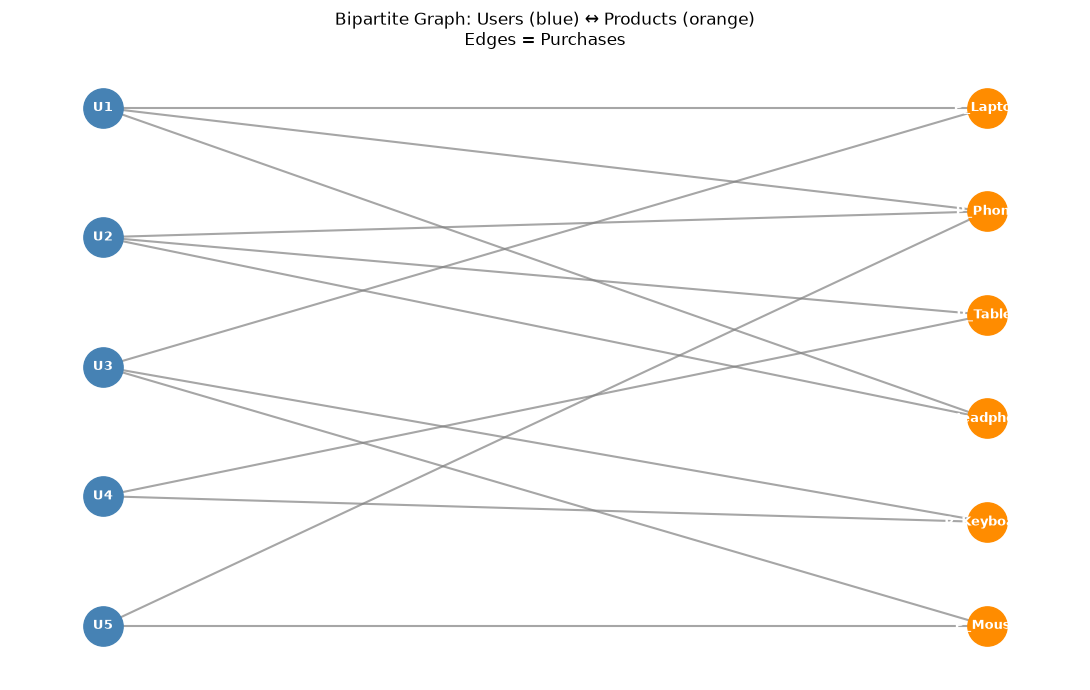

In [5]:
# Visualize bipartite graph
plt.figure(figsize=(11, 7))
# Position users on left, products on right
left_pos  = {u: (0, i * 1.5) for i, u in enumerate(reversed(users))}
right_pos = {p: (3, i * 1.2) for i, p in enumerate(reversed(products))}
pos = {**left_pos, **right_pos}

nx.draw_networkx_nodes(REC, pos, nodelist=users,    node_color="steelblue",  node_size=800)
nx.draw_networkx_nodes(REC, pos, nodelist=products, node_color="darkorange", node_size=800)
nx.draw_networkx_labels(REC, pos, font_size=9, font_weight="bold", font_color="white")
nx.draw_networkx_edges(REC, pos, edge_color="gray", width=1.5, alpha=0.7)

plt.title("Bipartite Graph: Users (blue) ↔ Products (orange)\nEdges = Purchases",
          fontsize=12)
plt.axis("off")
plt.tight_layout()
plt.show()